In [1]:
from langchain_community.document_loaders import PyPDFLoader
import os
import shutil
shutil.rmtree('./chroma_db',ignore_errors=True)

C:\Users\judes\AppData\Local\Temp\ipykernel_14304\2358273438.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
C:\Users\judes\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print(os.getcwd())

c:\Users\judes\coding\ML\astro_explainer


In [3]:
loader=PyPDFLoader(file_path='c:/Users/judes/coding/ML/astro_explainer/data/astronomy-2e.pdf')
pages=loader.load()

In [4]:
print(len(pages))

1151


In [5]:
print(pages[153].page_content[:300])

A. rises at 3:00 p.m.? 
B. is highest in the sky at sunrise? 
C. sets at 10:00 a.m.? 
28 . A car accident occurs around midnight on the night of a full moon. The driver at fault claims he was 
blinded momentarily by the Moon rising on the eastern horizon. Should the police believe him? 
29 . The sec


In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=0)
chunks=splitter.split_documents(pages)
print(len(chunks))

3839


In [7]:
chunks[100]

Document(metadata={'producer': 'Prince 16.2 (www.princexml.com)', 'creator': 'PyPDF', 'creationdate': '2026-04-20T12:09:42-05:00', 'moddate': '2026-04-20T12:09:42-05:00', 'title': 'Astronomy 2e', 'source': 'c:/Users/judes/coding/ML/astro_explainer/data/astronomy-2e.pdf', 'total_pages': 1151, 'page': 44, 'page_label': '45'}, page_content='sophisticated light-amplifying devices, and painstaking labor. Every clear night, at observatories around the \nworld, astronomers and students are at work on such mysteries as the birth of new stars and the large-scale \nstructure of the universe, fitting their results into the tapestry of our understanding. \n1.8 The Universe of the Very Small \nThe foregoing discussion has likely impressed on you that the universe is extraordinarily large and \nextraordinarily empty. On average, it is 10,000 times more empty than our Galaxy. Yet, as we have seen, even \nthe Galaxy is mostly empty space. The air we breathe has about 1019 atoms in each cubic centimete

In [8]:
for chunk in chunks:
    chunk.page_content=chunk.page_content.replace("\n",' ').strip()

In [9]:
chunks[100]

Document(metadata={'producer': 'Prince 16.2 (www.princexml.com)', 'creator': 'PyPDF', 'creationdate': '2026-04-20T12:09:42-05:00', 'moddate': '2026-04-20T12:09:42-05:00', 'title': 'Astronomy 2e', 'source': 'c:/Users/judes/coding/ML/astro_explainer/data/astronomy-2e.pdf', 'total_pages': 1151, 'page': 44, 'page_label': '45'}, page_content='sophisticated light-amplifying devices, and painstaking labor. Every clear night, at observatories around the  world, astronomers and students are at work on such mysteries as the birth of new stars and the large-scale  structure of the universe, fitting their results into the tapestry of our understanding.  1.8 The Universe of the Very Small  The foregoing discussion has likely impressed on you that the universe is extraordinarily large and  extraordinarily empty. On average, it is 10,000 times more empty than our Galaxy. Yet, as we have seen, even  the Galaxy is mostly empty space. The air we breathe has about 1019 atoms in each cubic centimeter—and 

In [10]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
embeddings=HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store=Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    persist_directory='./chroma_db'
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1193.90it/s]


In [11]:
results=vector_store.similarity_search('why do stars twinkle ',k=5)
for r in results:
    print(r.page_content[:200],'\n---')

“twinkling” of stars seen from Earth. The light beams are bent enough that part of the time they reach your  eye, and part of the time some of them miss, thereby making the star seem to vary in bright 
---
winds, often in different directions at different altitudes. As a result, the path followed by the light is constantly  changing.  For an analogy, think about watching a parade from a window high up i 
---
the nebula to glow so brightly. In these images, we see a section of the nebula in (a) visible light and (b) infrared. The four bright  stars in the center of the visible-light image are the Trapezium 
---
Earth’s atmosphere are transparent. As sunlight comes in, it scatters from the molecules of air. The small size  of the molecules means that the blue colors scatter much more efficiently than the gree 
---
emit at 3.6 microns (blue in this image), 8.0 microns (green), and 24 microns (red). The densest regions of dust are so cold and  opaque that they appear as dark clouds even at

In [12]:
print(vector_store._collection.count())

3839


In [13]:
import requests
resp=requests.get("https://api.nasa.gov/planetary/apod",params={'api_key':'UqQ5XoT0lCsYlRUHmX4sOpEZRgNUY5VOTbo55cGC'})
print(resp.json())

{'copyright': 'Mark Killion', 'date': '2026-09-07', 'explanation': "The Pelican Nebula is slowly being transformed.  IC 5070 (an official designation) is divided from the larger North America Nebula by a molecular cloud filled with dark dust.  The deep featured picture from Utah, USA incorporates 25 hours of exposure and brings out great details of this filamentary dust. The Pelican Nebula receives much study because it is a particularly active mix of star formation and evolving gas clouds.  The light from young energetic stars is slowly transforming the cold gas to hot gas, with the advancing boundary between the two, known as an ionization front, visible in bright orange on the upper right. Particularly dense tentacles of cold gas remain.  Millions of years from now, the Pelican Nebula, bounded by dark nebula LDN 935, might no longer be known as the Pelican, as the balance and placement of stars and gas will surely leave something that appears completely different.   APOD's main NASA

In [14]:
from langchain_core.tools import tool
@tool
def get_ast_pic()->str:
    """Fetch todays NASA Astronomy picture of the day, including title and explanation"""
    resp=requests.get("https://api.nasa.gov/planetary/apod",params={'api_key':'UqQ5XoT0lCsYlRUHmX4sOpEZRgNUY5VOTbo55cGC'})
    data=resp.json()
    return f"{data['title']}:{data['explanation']}"


In [15]:
ast_pic=get_ast_pic.invoke({})
print(ast_pic)

The Pelican Nebula in Gas, Dust, and Stars:The Pelican Nebula is slowly being transformed.  IC 5070 (an official designation) is divided from the larger North America Nebula by a molecular cloud filled with dark dust.  The deep featured picture from Utah, USA incorporates 25 hours of exposure and brings out great details of this filamentary dust. The Pelican Nebula receives much study because it is a particularly active mix of star formation and evolving gas clouds.  The light from young energetic stars is slowly transforming the cold gas to hot gas, with the advancing boundary between the two, known as an ionization front, visible in bright orange on the upper right. Particularly dense tentacles of cold gas remain.  Millions of years from now, the Pelican Nebula, bounded by dark nebula LDN 935, might no longer be known as the Pelican, as the balance and placement of stars and gas will surely leave something that appears completely different.   APOD's main NASA site is moving: From apo

In [16]:
from typing import Annotated,Sequence,TypedDict
from langgraph.graph import StateGraph,END
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq
from dotenv import load_dotenv
load_dotenv()
class AgentState(TypedDict):
    question:str
    route:str
    answer:str


llm=ChatGroq(model="openai/gpt-oss-120b",temperature=0)


In [17]:
classify_promp=ChatPromptTemplate.from_template("""
Classify this astronomy question into exactly one cateogry
- "retrieve": conceptual/factual questions about astronomy (e.g. "why do stars twinkle")
- "call_api": questions about what's visible or happening right now/today
- "clarify": ambiguous questions that need more detail

Question:{question}
Respond with only one word: call_api,retrieve,clarify
""")

def classify_node(state:AgentState):
    chain=classify_promp| llm
    result=chain.invoke({'question':state['question']})
    route=result.content.strip().lower()
    print(f"DEBUG:classified:'{state['question']}'as ->{route}")
    return {'route':route}

In [18]:
test_state={'question':'why do stars twinkle','route':"",'answer':''}
out=classify_node(test_state)
print(out)

DEBUG:classified:'why do stars twinkle'as ->retrieve
{'route': 'retrieve'}


In [19]:
test_questions = [
    "why do stars twinkle",                         
    "what's the astronomy picture of the day today",
    "tell me about space",                           
    "how far away is the moon",                       
    "what's visible in the sky tonight",              
]

for q in test_questions:
    state = {"question": q, "route": "", "answer": ""}
    result = classify_node(state)
    print(f"{q!r} -> {result['route']}")

DEBUG:classified:'why do stars twinkle'as ->retrieve
'why do stars twinkle' -> retrieve
DEBUG:classified:'what's the astronomy picture of the day today'as ->call_api
"what's the astronomy picture of the day today" -> call_api
DEBUG:classified:'tell me about space'as ->clarify
'tell me about space' -> clarify
DEBUG:classified:'how far away is the moon'as ->retrieve
'how far away is the moon' -> retrieve
DEBUG:classified:'what's visible in the sky tonight'as ->call_api
"what's visible in the sky tonight" -> call_api


In [20]:
answer_prompt=ChatPromptTemplate.from_template(""" 
Answer the astronomy question using only the context provided below.
If the context doesn't contain enough information, say so honestly


Context:{context}
Question:{question}

Answer:
""")

def retrieve_node(state:AgentState):
    results=vector_store.similarity_search(state['question'],k=3)
    context='\n\n'.join([r.page_content for r in results])

    chain=answer_prompt | llm
    response=chain.invoke({'context':context,'question':state['question']})
    return {'answer':response.content}

In [21]:
test_state={"question":"why do stars twinkle",'route':'retrieve','answer':''}
output=retrieve_node(test_state)
print(output['answer'])

Stars appear to twinkle because their light must pass through Earth’s atmosphere before it reaches our eyes or a telescope.  The atmosphere is full of turbulent air currents that move in different directions at different altitudes. As the parallel beams of starlight travel through these moving “cells” of air, each beam is bent slightly in a different way. Sometimes the bending directs the light into the eye, and at other moments the bending sends some of the light away. This continual, rapid change in the direction of the light makes the star’s brightness seem to vary, producing the familiar “twinkling” effect.  In space, where there is no atmosphere, the light from a star travels in a straight, steady line and does not twinkle.


In [22]:
def call_Api_node(state:AgentState):
    result=get_ast_pic.invoke({})
    return {'answer':result}

In [23]:
def clarify_node(state:AgentState):
    return {'answer':' Could you  be more specific? For example are you asking about a general astronomy concept or something thats visible in the sky currently'}

In [24]:
fake_context='this document does not contain information about stars or twinkling'
chain=answer_prompt | llm
response=chain.invoke({"context":fake_context,"question":"why do stars twinkle"})
print(response.content)

The provided context does not contain any information about stars or why they twinkle, so I cannot answer the question based on the given material.


In [27]:
graph=StateGraph(AgentState)
graph.add_node('classify',classify_node)
graph.add_node('retrieve',retrieve_node)
graph.add_node('call_api',call_Api_node)
graph.add_node('clarify',clarify_node)

graph.set_entry_point('classify')
graph.add_conditional_edges('classify',
                            lambda state:state['route'],
                            {'retrieve':'retrieve','call_api':'call_api','clarify':'clarify'})
graph.add_edge('retrieve',END)
graph.add_edge('call_api', END)
graph.add_edge('clarify',END)
app=graph.compile()

In [29]:
test_questions=[
    "why do stars twinkle",
    "what's the astronomy picture of the day today",
    "tell me about space",
    "how far away is the moon",
    "what's visible in the sky tonight",
]

for q in test_questions:
    results=app.invoke({'question':q,'route':'','answer':''})
    print(f"Question:{q}")
    print(f"Route: {results['route']}")
    print(f"Answer:{results['answer'][:200]}")
    print('---')

DEBUG:classified:'why do stars twinkle'as ->retrieve
Question:why do stars twinkle
Route: retrieve
Answer:Stars appear to twinkle because their light must pass through Earth’s atmosphere before it reaches our eyes or a telescope.  The atmosphere is full of turbulent air currents that move in different dir
---
DEBUG:classified:'what's the astronomy picture of the day today'as ->call_api
Question:what's the astronomy picture of the day today
Route: call_api
Answer:The Pelican Nebula in Gas, Dust, and Stars:The Pelican Nebula is slowly being transformed.  IC 5070 (an official designation) is divided from the larger North America Nebula by a molecular cloud fille
---
DEBUG:classified:'tell me about space'as ->clarify
Question:tell me about space
Route: clarify
Answer: Could you  be more specific? For example are you asking about a general astronomy concept or something thats visible in the sky currently
---
DEBUG:classified:'how far away is the moon'as ->retrieve
Question:how far away is t

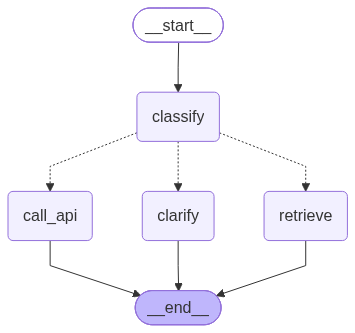

In [31]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))